# Predicting the next year's sale prices

Can the attributes in Price Paid Data price a sale that has not happened yet?

The target is the price on the transfer deed, in pounds. The model is trained on the log price, because a £20,000 miss should not count the same on a £150,000 terrace and an £800,000 detached house. Every metric below is converted back to pounds.

Features are the ones the file actually supports: property type, new build, tenure, region, postcode district, calendar month, and a time index (months since January 2024). There is no floor area, bedroom count, or condition, so a large residual is the expected result, not a tuning failure.

Postcode district has a few thousand levels. scikit-learn's histogram gradient boosting only accepts categorical features with up to 255 levels, so the booster is LightGBM, which splits high-cardinality categories directly.


## Train, early stopping, and test

The split is by transfer date.

| Window | Dates | Role |
| --- | --- | --- |
| Fit | January 2024 – September 2025 | Grow trees |
| Early stopping | October 2025 – December 2025 | Choose the number of trees |
| Refit | January 2024 – December 2025 | Final model, with that number of trees |
| Test | January 2026 – July 2026 | Reported metrics only |

August and September 2026 are left out of the test because registration is still incomplete. A random split would leak later sales from the same district into training and overstate accuracy.


In [1]:
%matplotlib inline

from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

def show(fig):
    display(fig)
    plt.close(fig)

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from house_prices.modeling import (
    fit_price_model,
    permutation_importance_pounds,
    predict_global_median,
    predict_hierarchical_median,
    predict_prices,
    regression_metrics,
    time_split,
)
from house_prices.plotting import (
    format_gbp,
    plot_error_by_region,
    plot_feature_importance,
    plot_model_comparison,
    plot_pred_vs_actual,
)
from house_prices.prepare import load_or_build
from house_prices.schema import FIGURE_DIR, MODEL_METRICS_PATH

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
sales = load_or_build()
train, test = time_split(sales)
print(
    f"Train {train['transfer_date'].min():%d %b %Y} – {train['transfer_date'].max():%d %b %Y}: {len(train):,} sales"
)
print(
    f"Test  {test['transfer_date'].min():%d %b %Y} – {test['transfer_date'].max():%d %b %Y}: {len(test):,} sales"
)


Train 01 Jan 2024 – 31 Dec 2025: 1,586,030 sales
Test  01 Jan 2026 – 31 Jul 2026: 331,973 sales


## Two baselines

The naive baseline predicts the training-window median for every sale. The strong baseline predicts the training median for the same postcode district and property type, and falls back to the district, then the region and type, then the region, then the global median when a group has no training sales. It is the right benchmark: most of what a price model can learn from this file is "what homes like this sold for in this district".


In [2]:
baseline_rows = list(zip(train["postcode_district"], train["property_type"]))
seen = set(baseline_rows)
test_keys = list(zip(test["postcode_district"], test["property_type"]))
share_seen = float(np.mean([(key in seen) for key in test_keys]))

predictions = {
    "Global median": predict_global_median(train, test),
    "District × type median": predict_hierarchical_median(train, test),
}
print(f"{share_seen:.1%} of test sales have a district and property type already seen in training.")


100.0% of test sales have a district and property type already seen in training.


## Gradient boosting

Early stopping watches squared error on the log price for October–December 2025. The test year is not used to pick the number of trees. The final model is then refit on all of 2024 and 2025.


In [3]:
model, builder, info = fit_price_model(train)
predictions["Gradient boosting"] = predict_prices(model, builder, test)
print(
    f"Early stopping selected {info['n_iter']} trees "
    f"({info['n_fit']:,} fit sales, {info['n_validation']:,} validation sales)."
)


/home/ubuntu/.local/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Early stopping selected 430 trees (1,374,210 fit sales, 211,820 validation sales).


,model,mae,rmse,r2,median_ae
0,Global median,"£161,221","£277,071",-0.048,"£110,000"
1,District × type median,"£87,947","£170,681",0.602,"£48,750"
2,Gradient boosting,"£87,454","£168,756",0.611,"£49,061"


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


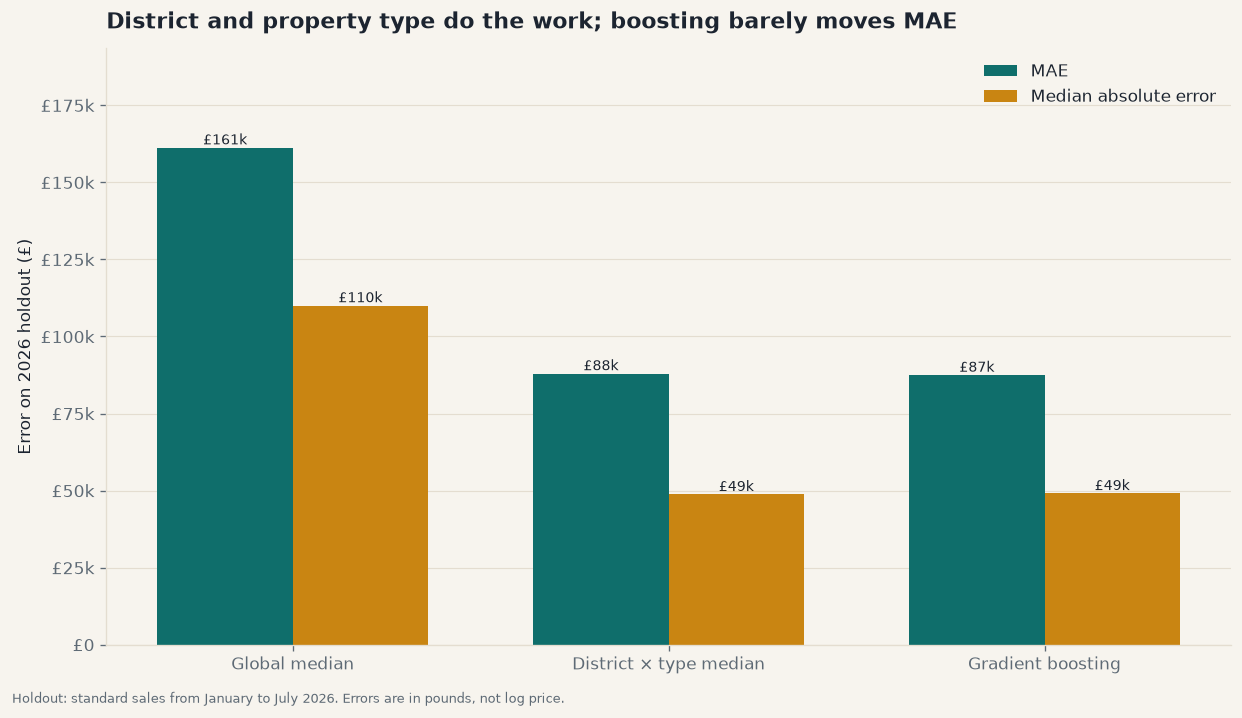

On the 2026 holdout the global training median misses by **£161,221** on average (median absolute error £110,000). A training median for the same postcode district and property type cuts MAE to **£87,947** and median absolute error to **£48,750** (R² 0.60). Gradient boosting reaches MAE **£87,454**, median absolute error **£49,061**, and R² **0.61**. That is a £493 MAE improvement, and the typical error is slightly worse. Once district and property type are known, the other fields in this file do not buy a better price.

In [4]:
rows = []
for name, predicted in predictions.items():
    scores = regression_metrics(test["price"].to_numpy(), predicted)
    scores["model"] = name
    rows.append(scores)
metrics = pd.DataFrame(rows)[["model", "mae", "rmse", "r2", "median_ae"]]
shown = metrics.copy()
for column in ["mae", "rmse", "median_ae"]:
    shown[column] = shown[column].map(lambda value: f"£{value:,.0f}")
shown["r2"] = shown["r2"].map(lambda value: f"{value:.3f}")
display(shown)

global_mae = float(metrics.loc[metrics["model"].eq("Global median"), "mae"].iloc[0])
district_mae = float(metrics.loc[metrics["model"].eq("District × type median"), "mae"].iloc[0])
boost_mae = float(metrics.loc[metrics["model"].eq("Gradient boosting"), "mae"].iloc[0])
boost_med = float(metrics.loc[metrics["model"].eq("Gradient boosting"), "median_ae"].iloc[0])
boost_r2 = float(metrics.loc[metrics["model"].eq("Gradient boosting"), "r2"].iloc[0])
lift = 1 - boost_mae / district_mae
if lift >= 0.02:
    comparison_title = (
        f"Gradient boosting lowers MAE from {format_gbp(district_mae)} to {format_gbp(boost_mae)}"
    )
else:
    comparison_title = "District and property type do the work; boosting barely moves MAE"
show(plot_model_comparison(metrics, FIGURE_DIR / "10_model_comparison.png", title=comparison_title))
def pounds(value: float) -> str:
    return f"£{value:,.0f}"

display(Markdown(
    f"On the 2026 holdout the global training median misses by **{pounds(global_mae)}** on average "
    f"(median absolute error {pounds(float(metrics.loc[metrics['model'].eq('Global median'), 'median_ae'].iloc[0]))}). "
    f"A training median for the same postcode district and property type cuts MAE to **{pounds(district_mae)}** "
    f"and median absolute error to **{pounds(float(metrics.loc[metrics['model'].eq('District × type median'), 'median_ae'].iloc[0]))}** "
    f"(R² {float(metrics.loc[metrics['model'].eq('District × type median'), 'r2'].iloc[0]):.2f}). "
    f"Gradient boosting reaches MAE **{pounds(boost_mae)}**, median absolute error **{pounds(boost_med)}**, "
    f"and R² **{boost_r2:.2f}**. "
    f"That is a £{district_mae - boost_mae:,.0f} MAE improvement, and the typical error is slightly worse. "
    "Once district and property type are known, the other fields in this file do not buy a better price."
))


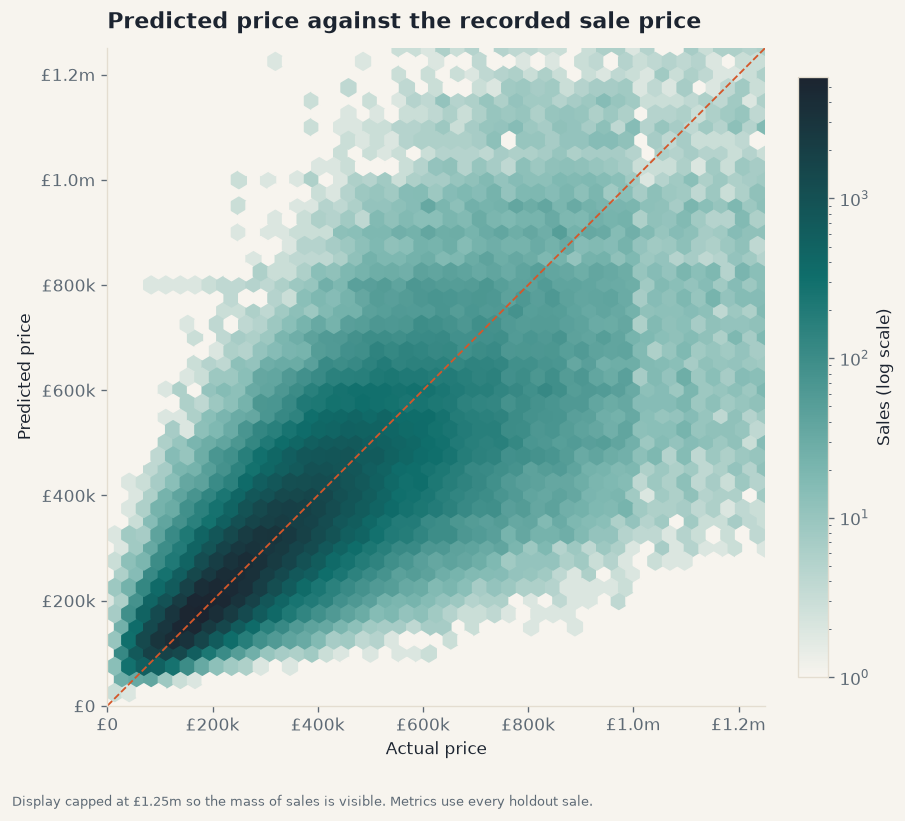

In [5]:
actual = test["price"].to_numpy()
predicted = predictions["Gradient boosting"]
show(plot_pred_vs_actual(actual, predicted, FIGURE_DIR / "11_predicted_vs_actual.png"))


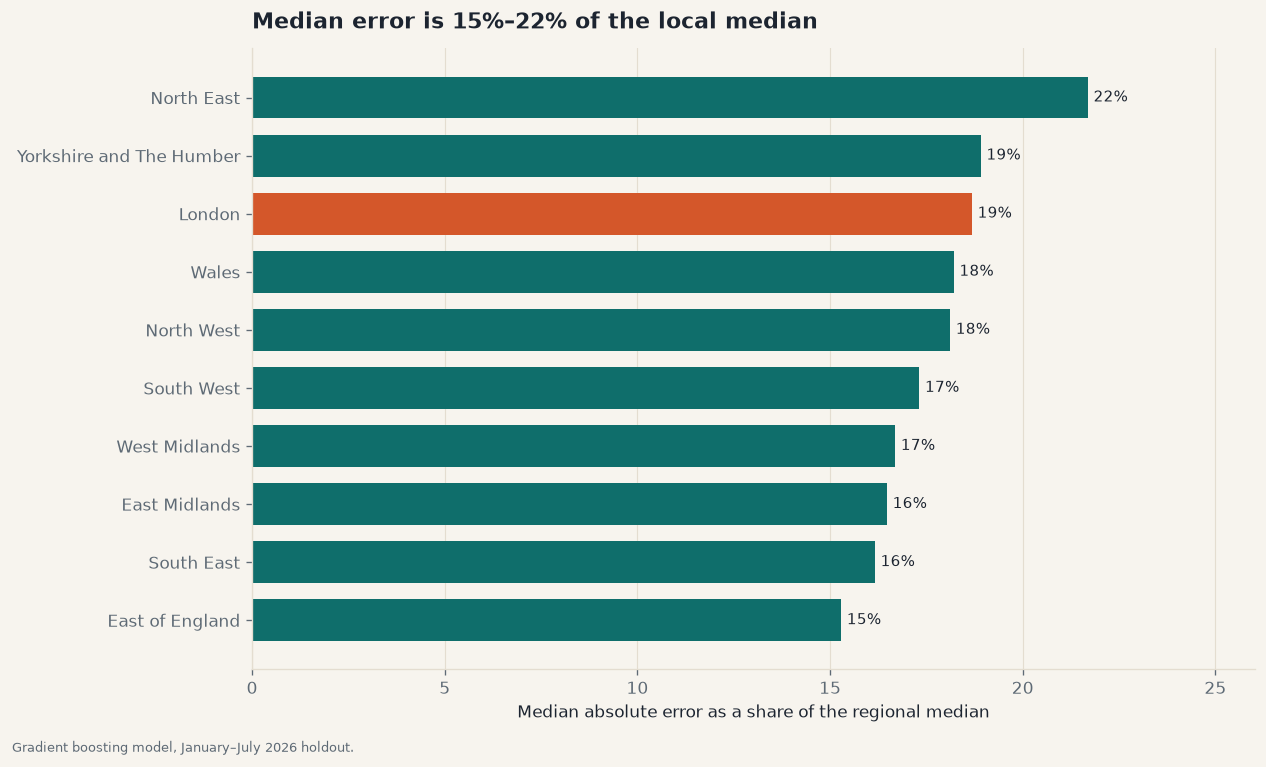

,region,median_ae,mae,median_price,sales,relative_ae
1,East of England,51741.175144,87683.610625,338450.0,37498,0.152877
5,South East,60614.907111,104453.165774,375000.0,56075,0.161640
0,East Midlands,40367.386997,64450.945436,245000.0,29323,0.164765
8,West Midlands,41722.941285,68869.453324,250000.0,30010,0.166892
6,South West,52813.613523,89290.134351,305000.0,37460,0.173159
4,North West,40757.275297,66888.904820,225000.0,42935,0.181143
7,Wales,39693.882624,60999.180282,218000.0,17650,0.182082
2,London,95273.373810,167680.516752,510000.0,33813,0.186811
9,Yorkshire and The Humber,39709.556511,64969.017482,210000.0,32060,0.189093
3,North East,36873.626685,58390.914900,170000.0,15149,0.216904


,property_type,median_ae,mae,median_price,relative_ae
2,Semi-detached,42914.108240,68599.654496,275000.0,0.156051
3,Terraced,37787.302641,65837.660539,240000.0,0.157447
0,Detached,87625.256417,138937.403521,420000.0,0.208632
1,Flat,46254.241419,83730.560157,220141.0,0.210112


In [6]:
scored = test[["region", "property_type", "price"]].copy()
scored["abs_error"] = np.abs(predictions["Gradient boosting"] - scored["price"].to_numpy())
by_region = (
    scored.groupby("region")
    .agg(median_ae=("abs_error", "median"), mae=("abs_error", "mean"), median_price=("price", "median"), sales=("price", "size"))
    .reset_index()
)
by_region["relative_ae"] = by_region["median_ae"] / by_region["median_price"]
rel_title = (
    "Median error is "
    f"{by_region['relative_ae'].min():.0%}–{by_region['relative_ae'].max():.0%} of the local median"
)
show(plot_error_by_region(by_region, FIGURE_DIR / "12_error_by_region.png", title=rel_title))
by_type = (
    scored.groupby("property_type")
    .agg(median_ae=("abs_error", "median"), mae=("abs_error", "mean"), median_price=("price", "median"))
    .reset_index()
)
by_type["relative_ae"] = by_type["median_ae"] / by_type["median_price"]
display(by_region.sort_values("relative_ae"))
display(by_type.sort_values("relative_ae"))


## Which features the model actually uses

Permutation importance shuffles one column at a time on a 12,000-sale sample of the holdout and records the increase in pound MAE. Region and postcode district are nested, so their importances are not separate effects: shuffling either one breaks the location path through the trees. Read them together. A near-zero or slightly negative figure means that column, on its own, did not help the holdout.


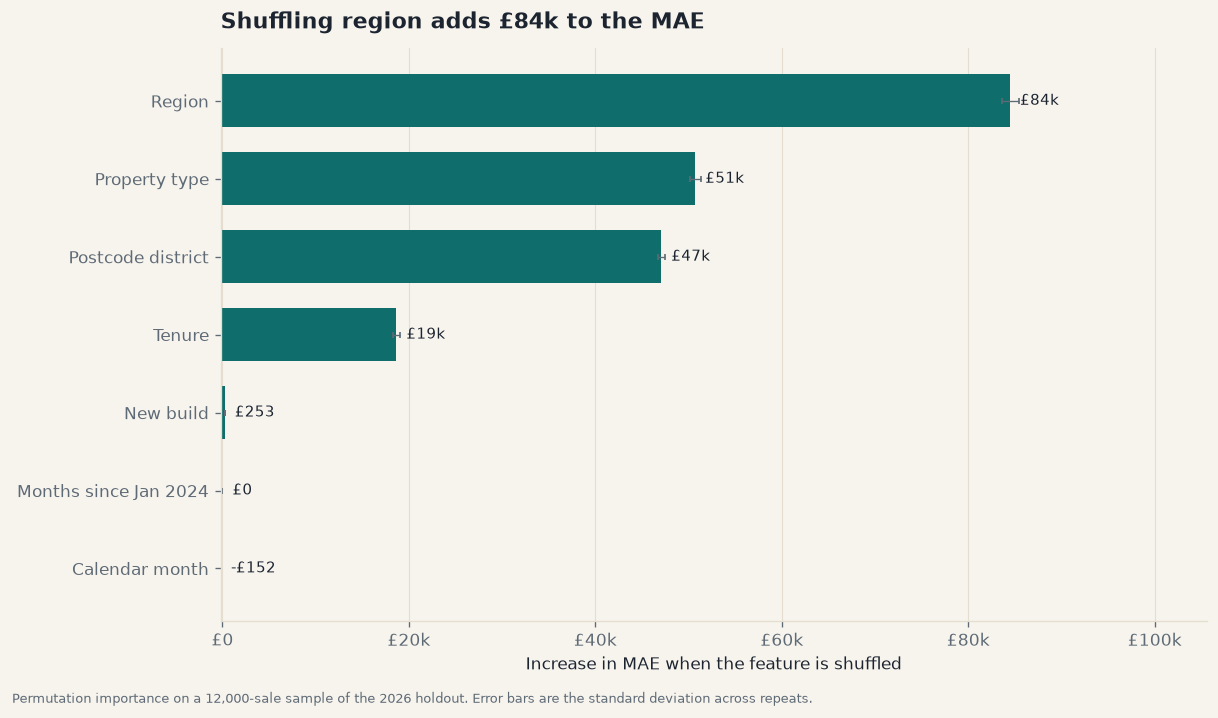

,feature,label,mae_increase,mae_increase_std
0,region,Region,84480.971704,919.380772
1,property_type,Property type,50716.790944,608.388640
2,postcode_district,Postcode district,47068.629145,369.365368
3,tenure,Tenure,18659.043298,339.511892
4,new_build,New build,252.981268,19.349321
5,time_index,Months since Jan 2024,0.000000,0.000000
6,month,Calendar month,-151.601592,40.191709


In [7]:
importance = permutation_importance_pounds(model, builder, test)
top = importance.iloc[0]
show(plot_feature_importance(
    importance,
    FIGURE_DIR / "13_feature_importance.png",
    title=f"Shuffling {top['label'].lower()} adds {format_gbp(top['mae_increase'])} to the MAE",
))
importance


In [8]:
payload = {
    "n_train": int(len(train)),
    "n_test": int(len(test)),
    "train_start": str(train["transfer_date"].min().date()),
    "train_end": str(train["transfer_date"].max().date()),
    "test_start": str(test["transfer_date"].min().date()),
    "test_end": str(test["transfer_date"].max().date()),
    "share_test_seen_in_training": share_seen,
    "n_iter": info["n_iter"],
    "n_fit": info["n_fit"],
    "n_validation": info["n_validation"],
    "metrics": metrics.to_dict(orient="records"),
    "importance": importance.to_dict(orient="records"),
    "error_by_region": by_region.to_dict(orient="records"),
    "error_by_type": by_type.to_dict(orient="records"),
}
MODEL_METRICS_PATH.write_text(json.dumps(payload, indent=2) + "\n", encoding="utf-8")
print(f"Wrote {MODEL_METRICS_PATH}")


Wrote /workspace/reports/model_metrics.json


## What this does not support

The holdout error is still tens of thousands of pounds. That is enough to describe the market and to beat a naive price, and it is not a valuation. The file has no size, condition, lease length, or service charge. Postcode district is a coarse location. Category B sales, Scotland, and Northern Ireland are out of scope. The last two months of the extract are incomplete and were not scored. A buyer, a lender, or a tax valuation should not use these predictions as a price.
